# 05 Validation against the USGS creepmeters, and the aperture choice

```
Created on Mon Sep 21 2026
@author: daniellelindsay
Run in opera_disp_feb13. The bootstraps take ~2 min; the ladder scoring reads
the frozen sweep directories and takes ~1 min.
```

**What this notebook does.** It compares the InSAR creep with the five USGS
creepmeters over the same window, three ways, all from the same stacked
time series (Methods M4):

- **creepmeter**: the instrument's own rate (ground truth, already fault-parallel)
- **crossing**: the InSAR fault-parallel creep rate from `fp_ts.csv` (notebook 03),
  the narrow-aperture like-for-like match to a point instrument
- **step**: the fault-crossing step in the fault-parallel velocity field
  (notebook 02 transects, +/-1000 m), which also carries the distributed part

Every rate uncertainty is a moving-block bootstrap 95% confidence interval
(blocks of ~1 yr in time, ~100 m in distance), because both the time series
and the profiles are autocorrelated and an ordinary standard error would be
2 to 3 times too small. The detrended comparison gives the transient noise
floor that the event detector (05) needs.

The second part draws the **aperture ladder**: why the creep time series use
the 30 to 150 m bin. The sweep itself was run once in July/August 2026
(`Hayward_DISP-S1/analysis/run11b_sweep_ladder.py`); its outputs are read
here as frozen inputs (fingerprinted in the registry) and re-scored on a
fixed stack. It is not re-run (Dani, 2026-09-21).

Ported from `Hayward_DISP-S1/analysis/run10_creepmeter_validation.py`,
`plotting/fig_validation.py` and `plotting/figS_binning_ladder.py`.

**Outputs** (`outputs/05_validation/`): `station_agreement.csv`,
`sweep_ladder_scores.csv`, `04_validation_stats.txt`, registry rows `05_*`.

**Figures**: the five-station validation figure (supplement) and the ladder.

**What to check.** CFW1, CTM1 and CPP1 should agree with the creepmeters to a
few tenths of a millimetre a year; COZ1 is the known low outlier (the InSAR
recovers only part of its two large creep events); CHP1 runs high because
its creep is distributed over ~300 m. The detrended RMSE per station (~1.6 to
1.8 mm) is the single-crossing noise floor quoted in the text.

In [1]:
import os
import json
import warnings

import insar_utils as utils
from TulePond_filepaths import (common_paths, creepmeters, segments, params, x_width,
                                dist_min, dist_max, coh_timeseries, min_points, coh_velocity,
                                paths_out, repo_dir)

import numpy as np
import pandas as pd
import h5py
import pyproj
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.font_manager import FontProperties
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

## Constants

In [2]:
notebook = "05_validation"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

block_years = 1.0     # moving-block length for the time bootstraps (carries the annual cycle)
block_m = 100.0       # moving-block length (m) for the spatial step bootstrap
nboot = 2000          # bootstrap resamples
seed = 0
stack_km = 0.2        # half-window of fp_ts rows to stack at a creepmeter (matches the 400 m swath)
stack_widen_km = 1.0  # widen to this if the 0.2 km window has < 2 usable rows (CPP1 at the frame edge)
stack_max = 5         # cap the stack at the N nearest usable rows
swath_m, max_dist_m = 200.0, 1000.0   # the notebook 02 transects
strike = 144.0        # page rotation of the map panel (mean strike, notebook 02)
map_half_km = 10.0    # map panel cross-fault half-width
ref_patch_km = 5.0    # map display reference: CTM1-COZ1 patch, +/- this across the fault

# the COZ1 creep events the creepmeter recorded, used to score how much of the
# step each aperture recovers (ladder panel d); windows from the creepmeter record
coz1_events = [(2018.997, 2019.121), (2022.093, 2022.219)]
collar_yr = 0.75      # inter-event collar each side of a window for the local trend

# the ladder: bins scored on a FIXED stack (4 rows within 0.4 km, no widening)
# so every bin averages the same number of rows. The sweep was run at coherence
# 0.9; the three-threshold comparison of the chosen bin (below) is what justifies
# running the paper's stream at 0.7.
ladder_coh = 0.9
ladder_stack_km, ladder_n_stack = 0.4, 4
fixed_width = [(0, 100), (50, 150), (100, 200), (150, 250), (200, 300), (300, 400), (400, 500)]
growing = [(100, 200), (100, 300), (100, 400), (100, 500), (100, 700)]
original = [(0, 60), (30, 90), (60, 120), (0, 120), (30, 150), (60, 180), (200, 600), (500, 700)]
inner_edge = [(0, 150), (10, 150), (20, 150), (30, 150), (40, 150), (50, 150), (60, 150), (70, 150), (80, 150)]
selected = (int(dist_min * 1000), int(dist_max * 1000))      # the bin the paper uses
kernel_m = (55, 65)   # measured DISP-S1 phase-linking half-width, before / after the 2024-25 reprocessing

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
xf_file = os.path.join(paths_out["02_velocity_decomposition"], f"fp_velocity_xfault_swath{swath_m:.0f}m_dist{max_dist_m:.0f}m.csv")
map_file = os.path.join(paths_out["02_velocity_decomposition"], "fp_velocity_map.h5")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
lengths_file = os.path.join(paths_out["04_event_detection"], "section_lengths.csv")   # the measured section extents

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(fp_ts_file, xf_file, map_file, lengths_file, events_file, common_paths["fault_profiles"],
           *[utils.creepmeter_file(common_paths["creepmeter_dir"], c[0]) for c in creepmeters],
           os.path.join(common_paths["sweep_dir"], "sweep_summary_ladder_coh0.9_mp5.csv"))

Registry for 05_validation: run c41647c2, git nogit+


## LOAD: the creep time series, the transects and the creepmeters

The creepmeter records are daily means over the InSAR window with gross
glitches removed (a robust filter; CPP1 has spikes to -338 mm). The InSAR
"stack" at a creepmeter is the mean of the nearest usable `fp_ts` rows within
200 m along strike (up to 5 rows), which is the like-for-like match to the
400 m transect swath.

In [3]:
fp_ts = pd.read_csv(fp_ts_file, index_col=0)
fp_ts.columns = fp_ts.columns.astype(float)
fp_ts.index = fp_ts.index.astype(float)
t0, t1 = float(fp_ts.columns.min()), float(fp_ts.columns.max())
xf = pd.read_csv(xf_file)
print(f"fp_ts: {fp_ts.shape[0]} crossings x {fp_ts.shape[1]} epochs, window {t0:.3f} to {t1:.3f} ({t1 - t0:.2f} yr)")
print(f"transects: {len(xf)} pixels at {xf.code.nunique()} creepmeters")


def daily_creepmeter(code):
    """Creepmeter cumulative slip over the InSAR window, glitch-filtered and daily-averaged."""
    cm = utils.read_creepmeter_10min(utils.creepmeter_file(common_paths["creepmeter_dir"], code),
                                     date_start=t0, date_end=t1)
    sl = cm["slip_mm"].values
    med = np.median(sl)
    mad = np.median(np.abs(sl - med)) or 1.0
    cm = cm[np.abs(sl - med) < 6 * 1.4826 * mad + 10].reset_index(drop=True)
    return cm["decimal_year"].values, cm["slip_mm"].values - cm["slip_mm"].values[0]


def stack_insar(fp, lat, half_km=stack_km, widen_km=stack_widen_km, n_stack=stack_max, exact=False):
    """Mean +/- std of the fp_ts rows nearest `lat`. `exact=True` (the ladder)
    requires n_stack usable rows inside half_km and never widens, so every bin
    is scored on the same number of rows. Returns (t, mean, std, n) or None."""
    nepoch = fp.shape[1]
    for km in ((half_km,) if exact else (half_km, widen_km)):
        dlat = km / 111.19
        sub = fp[(fp.index >= lat - dlat) & (fp.index <= lat + dlat)]
        usable = sub[sub.notna().sum(axis=1) > 0.5 * nepoch]
        if len(usable) >= 2:
            break
    if len(usable) == 0 or (exact and len(usable) < n_stack):
        return None
    usable = usable.iloc[np.argsort(np.abs(usable.index.values - lat))[:n_stack]]
    t = fp.columns.values.astype(float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return t, np.nanmean(usable.values, axis=0), np.nanstd(usable.values, axis=0), len(usable)


cm_data = {code: daily_creepmeter(code) for code, la, lo, name in creepmeters}
for code, la, lo, name in creepmeters:
    ct, ccum = cm_data[code]
    st = stack_insar(fp_ts, la)
    print(f"  {code} ({name}): creepmeter {len(ct)} days, {ccum[-1]:.1f} mm total; InSAR stack of {st[3] if st else 0} rows")

fp_ts: 609 crossings x 423 epochs, window 2016.672 to 2025.953 (9.28 yr)
transects: 3632 pixels at 5 creepmeters


  CPP1 (Pinole Point): creepmeter 3329 days, 47.8 mm total; InSAR stack of 4 rows
  CTM1 (Temescal): creepmeter 3129 days, 38.8 mm total; InSAR stack of 5 rows
  COZ1 (Oakland Zoo): creepmeter 3388 days, 39.3 mm total; InSAR stack of 5 rows
  CHP1 (Palisade Street): creepmeter 3257 days, 37.3 mm total; InSAR stack of 5 rows
  CFW1 (Fremont): creepmeter 3342 days, 65.2 mm total; InSAR stack of 5 rows


## RUN: rates with bootstrap confidence intervals

Per station: the creepmeter rate, the crossing rate and the velocity-field
step, each with a moving-block bootstrap 95% CI (residuals resampled in
contiguous blocks, re-added to the fitted trend, refitted). Then the
cumulative misfit, and the detrended comparison: the correlation of the two
detrended series (does the InSAR see the same transients?) and the detrended
RMSE (the single-station noise floor).

In [4]:
rng = np.random.default_rng(seed)


def slope(t, y):
    """OLS slope in closed form, so the bootstrap refit is fast."""
    tc = t - t.mean()
    return float(tc @ (y - y.mean()) / (tc @ tc))


def block_bootstrap_slope(x, y, block_len):
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)
    b = np.polyfit(x, y, 1)
    trend = np.polyval(b, x); resid = y - trend
    block_len = int(max(2, min(block_len, n)))
    n_blocks = int(np.ceil(n / block_len))
    out = np.empty(nboot)
    for k in range(nboot):
        starts = rng.integers(0, n - block_len + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + block_len) for s in starts])[:n]
        out[k] = slope(x, trend + resid[idx])
    return b[0], np.percentile(out, 2.5), np.percentile(out, 97.5)


def step_fit(d, v):
    """v = a + b*d + step*[d > 0]; the step is the fault-crossing creep rate."""
    G = np.column_stack([np.ones_like(d), d, (d > 0).astype(float)])
    a, b, step = np.linalg.lstsq(G, v, rcond=None)[0]
    return step, a + b * d + step * (d > 0)


def block_bootstrap_step(d, v):
    order = np.argsort(d); d, v = d[order], v[order]
    step0, pred = step_fit(d, v)
    resid = v - pred
    block_len = int(max(3, round(len(d) * block_m / (d.max() - d.min()))))
    n = len(d); n_blocks = int(np.ceil(n / block_len))
    out = np.empty(nboot)
    for k in range(nboot):
        starts = rng.integers(0, n - block_len + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + block_len) for s in starts])[:n]
        out[k], _ = step_fit(d, pred + resid[idx])
    return step0, np.percentile(out, 2.5), np.percentile(out, 97.5)


def largest_event(t, cum, win_days=60.0):
    """Largest rise in cumulative slip over any window up to win_days."""
    win = win_days / 365.25
    best = 0.0
    for i in range(0, len(t), 50):
        j = np.searchsorted(t, t[i] + win)
        if j < len(t):
            best = max(best, cum[j] - cum[i])
    return best


def n_eff(x):
    """Effective sample size under lag-1 autocorrelation."""
    x = x[np.isfinite(x)]; xm = x - x.mean()
    r1 = float(xm[1:] @ xm[:-1] / (xm @ xm))
    return len(x) * (1 - r1) / (1 + r1), r1


rows = []
for code, la, lo, name in creepmeters:
    ct, ccum = cm_data[code]
    dt = np.median(np.diff(ct))
    cm_rate, cm_lo, cm_hi = block_bootstrap_slope(ct, ccum, round(block_years / dt))
    t, mean, std, nstack = stack_insar(fp_ts, la)
    ok = np.isfinite(mean); ti, ins = t[ok], mean[ok]
    cr_rate, cr_lo, cr_hi = block_bootstrap_slope(ti, ins, round(block_years / np.median(np.diff(ti))))
    s = xf[(xf["code"] == code) & (xf["dist_m"].abs() <= max_dist_m)]
    st_rate, st_lo, st_hi = block_bootstrap_step(s["dist_m"].values.astype(float), s["fp_vel"].values.astype(float))
    cmi = np.interp(ti, ct, ccum)                      # creepmeter ON the SAR epochs
    res = ins - cmi
    di, dc = utils.detrend(ti, ins), utils.detrend(ti, cmi)
    gd = np.isfinite(di) & np.isfinite(dc)
    neff, r1 = n_eff(di[gd])
    rows.append(dict(code=code, name=name, nstack=nstack, nepoch=int(ok.sum()),
                     cm_rate=cm_rate, cm_lo=cm_lo, cm_hi=cm_hi, cr_rate=cr_rate, cr_lo=cr_lo, cr_hi=cr_hi,
                     st_rate=st_rate, st_lo=st_lo, st_hi=st_hi,
                     d_cross=cr_rate - cm_rate, d_step=st_rate - cm_rate, distributed=st_rate - cr_rate,
                     sig_cross=np.hypot((cr_hi - cr_lo) / 3.92, (cm_hi - cm_lo) / 3.92),
                     sig_step=np.hypot((st_hi - st_lo) / 3.92, (cm_hi - cm_lo) / 3.92),
                     cum_rmse=np.sqrt(np.mean(res ** 2)), cum_mad=1.4826 * np.median(np.abs(res - np.median(res))),
                     det_std_ins=np.nanstd(di), det_std_cm=np.nanstd(dc),
                     det_rmse=float(np.sqrt(np.mean((di[gd] - dc[gd]) ** 2))),
                     event_cm=largest_event(ct, ccum), det_r=float(np.corrcoef(di[gd], dc[gd])[0, 1]),
                     det_r1=r1, det_neff=neff))
    print(f"  {code}: creepmeter {cm_rate:5.2f} [{cm_lo:.2f}, {cm_hi:.2f}]  crossing {cr_rate:5.2f} [{cr_lo:.2f}, {cr_hi:.2f}]  "
          f"step {st_rate:5.2f} [{st_lo:.2f}, {st_hi:.2f}]  det r {rows[-1]['det_r']:.2f}  det RMSE {rows[-1]['det_rmse']:.2f} mm")
df = pd.DataFrame(rows).set_index("code")
df.to_csv(os.path.join(out_dir, "station_agreement.csv"))

  CPP1: creepmeter  5.05 [4.95, 5.15]  crossing  5.11 [4.82, 5.39]  step  3.77 [2.56, 4.88]  det r 0.26  det RMSE 1.86 mm


  CTM1: creepmeter  4.11 [4.01, 4.22]  crossing  4.30 [4.03, 4.59]  step  3.73 [3.20, 4.23]  det r 0.40  det RMSE 1.82 mm


  COZ1: creepmeter  4.48 [4.14, 4.80]  crossing  3.15 [2.89, 3.38]  step  3.14 [2.62, 3.67]  det r 0.58  det RMSE 1.68 mm


  CHP1: creepmeter  3.79 [3.73, 3.84]  crossing  4.24 [4.14, 4.34]  step  4.98 [4.32, 5.62]  det r -0.18  det RMSE 1.58 mm


  CFW1: creepmeter  6.99 [6.76, 7.23]  crossing  6.59 [6.46, 6.70]  step  6.64 [6.18, 7.09]  det r 0.35  det RMSE 1.47 mm


## Ensemble agreement and the noise floor

Agreement is reported three ways because no single number suffices: rate
residual statistics (bias, RMS, reduced chi-square against the combined
CI), the same excluding COZ1, and the detrended RMSE. Two noise-floor
definitions are printed side by side; the text quotes the mean detrended
RMSE (~1.7 mm at a single crossing).

In [5]:
def agreement(sub, key):
    delta = sub[f"d_{key}"].values; sig = sub[f"sig_{key}"].values
    w = 1.0 / sig ** 2; bias = np.mean(delta); sd = np.std(delta, ddof=1)
    return dict(bias=bias, median_bias=np.median(delta), wrms=np.sqrt(np.sum(w * delta ** 2) / np.sum(w)),
                rms=np.sqrt(np.mean(delta ** 2)), chi2v=np.mean((delta / sig) ** 2),
                ba_lo=bias - 1.96 * sd, ba_hi=bias + 1.96 * sd, maxabs=np.max(np.abs(delta)))


agr = {"cross": agreement(df, "cross"), "step": agreement(df, "step"),
       "cross_excl_coz1": agreement(df.drop("COZ1"), "cross")}
steady = df[df.det_std_cm < 1.0]                 # stations whose creepmeter transient is sub-mm
floor_run10 = float(steady.det_std_ins.median())  # there the detrended InSAR is pure epoch noise
floor_rmse = float(df.det_rmse.mean())

L = ["=" * 78, "CREEPMETER vs INSAR: CREEP-RATE AGREEMENT", "=" * 78,
     f"InSAR window {t0:.3f} to {t1:.3f} ({t1 - t0:.2f} yr); creep bin {dist_min * 1000:.0f}-{dist_max * 1000:.0f} m, "
     f"along-strike +/-{x_width * 1000:.0f} m, coherence {coh_timeseries}",
     f"velocity-field step: +/-{max_dist_m:.0f} m transects, swath +/-{swath_m:.0f} m; InSAR stack <= {stack_max} rows within +/-{stack_km * 1000:.0f} m",
     f"bootstrap: {nboot} moving-block resamples (block ~{block_years:g} yr / {block_m:.0f} m), seed {seed}", "",
     "PER-STATION RATES (mm/yr) [95% CI]",
     f"{'code':5} {'creepmeter':>22} {'crossing':>22} {'step':>22}"]
for c, r in df.iterrows():
    L.append(f"{c:5} {r.cm_rate:6.2f} [{r.cm_lo:5.2f},{r.cm_hi:5.2f}]   {r.cr_rate:6.2f} [{r.cr_lo:5.2f},{r.cr_hi:5.2f}]   "
             f"{r.st_rate:6.2f} [{r.st_lo:5.2f},{r.st_hi:5.2f}]")
L += ["", "DIFFERENCES vs CREEPMETER (mm/yr)", f"{'code':5} {'crossing-cm':>12} {'step-cm':>10} {'step-crossing':>14}"]
for c, r in df.iterrows():
    L.append(f"{c:5} {r.d_cross:12.2f} {r.d_step:10.2f} {r.distributed:14.2f}")
L += ["", "TIME-SERIES AGREEMENT (creepmeter aligned to the InSAR epochs)",
      f"{'code':5} {'cum RMSE':>9} {'det.std ins/cm':>16} {'det.r':>7} {'det RMSE':>9} {'N_eff':>7} {'N_ep':>5}"]
for c, r in df.iterrows():
    L.append(f"{c:5} {r.cum_rmse:9.2f} {r.det_std_ins:7.2f}/{r.det_std_cm:<7.2f} {r.det_r:7.2f} {r.det_rmse:9.2f} {r.det_neff:7.0f} {r.nepoch:5d}")
L += ["", "ENSEMBLE AGREEMENT"]
for key, lab in (("cross", "crossing vs creepmeter, all 5"), ("cross_excl_coz1", "crossing vs creepmeter, excl COZ1"),
                 ("step", "velocity step vs creepmeter, all 5")):
    a = agr[key]
    L += [f"{lab}: bias {a['bias']:+.2f} (median {a['median_bias']:+.2f}), RMS {a['rms']:.2f}, weighted RMS {a['wrms']:.2f}, "
          f"max |diff| {a['maxabs']:.2f} mm/yr, reduced chi2 {a['chi2v']:.2f}, Bland-Altman [{a['ba_lo']:+.2f}, {a['ba_hi']:+.2f}]"]
L += ["", "NOISE FLOOR",
      f"median detrended InSAR std at steady stations (creepmeter transient < 1 mm): {floor_run10:.2f} mm",
      f"mean detrended RMSE, InSAR minus creepmeter, all 5: {floor_rmse:.2f} mm (range {df.det_rmse.min():.2f} to {df.det_rmse.max():.2f})"]
print("\n".join(L))

CREEPMETER vs INSAR: CREEP-RATE AGREEMENT
InSAR window 2016.672 to 2025.953 (9.28 yr); creep bin 30-150 m, along-strike +/-200 m, coherence 0.7
velocity-field step: +/-1000 m transects, swath +/-200 m; InSAR stack <= 5 rows within +/-200 m
bootstrap: 2000 moving-block resamples (block ~1 yr / 100 m), seed 0

PER-STATION RATES (mm/yr) [95% CI]
code              creepmeter               crossing                   step
CPP1    5.05 [ 4.95, 5.15]     5.11 [ 4.82, 5.39]     3.77 [ 2.56, 4.88]
CTM1    4.11 [ 4.01, 4.22]     4.30 [ 4.03, 4.59]     3.73 [ 3.20, 4.23]
COZ1    4.48 [ 4.14, 4.80]     3.15 [ 2.89, 3.38]     3.14 [ 2.62, 3.67]
CHP1    3.79 [ 3.73, 3.84]     4.24 [ 4.14, 4.34]     4.98 [ 4.32, 5.62]
CFW1    6.99 [ 6.76, 7.23]     6.59 [ 6.46, 6.70]     6.64 [ 6.18, 7.09]

DIFFERENCES vs CREEPMETER (mm/yr)
code   crossing-cm    step-cm  step-crossing
CPP1          0.05      -1.29          -1.34
CTM1          0.19      -0.38          -0.56
COZ1         -1.33      -1.34          -0.01


## Figure: the five creepmeters against the InSAR

Column 1: the fault-parallel velocity map on a page rotated to the mean
strike (the trace stays curved), creepmeters as blue ticks, the event-driven
sections bracketed (from notebook 05 if it has run, else the section bounds).
Columns 2 to 4, one row per creepmeter north to south: the cross-fault
velocity profile with its step; cumulative creep, creepmeter (blue) against
InSAR (grey, +/-1 std of the stacked rows); the same detrended, with the COZ1
creep-event windows in gold.

section brackets (lat): {'Tule Pond': (np.float64(37.5344), np.float64(37.5801)), 'Oakland': (np.float64(37.7365), np.float64(37.766))}


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/figS_validation_cohmap0.7_ap30-150m_coh0.7_mp5_sw200m_profile1000m_stack5x200m.png


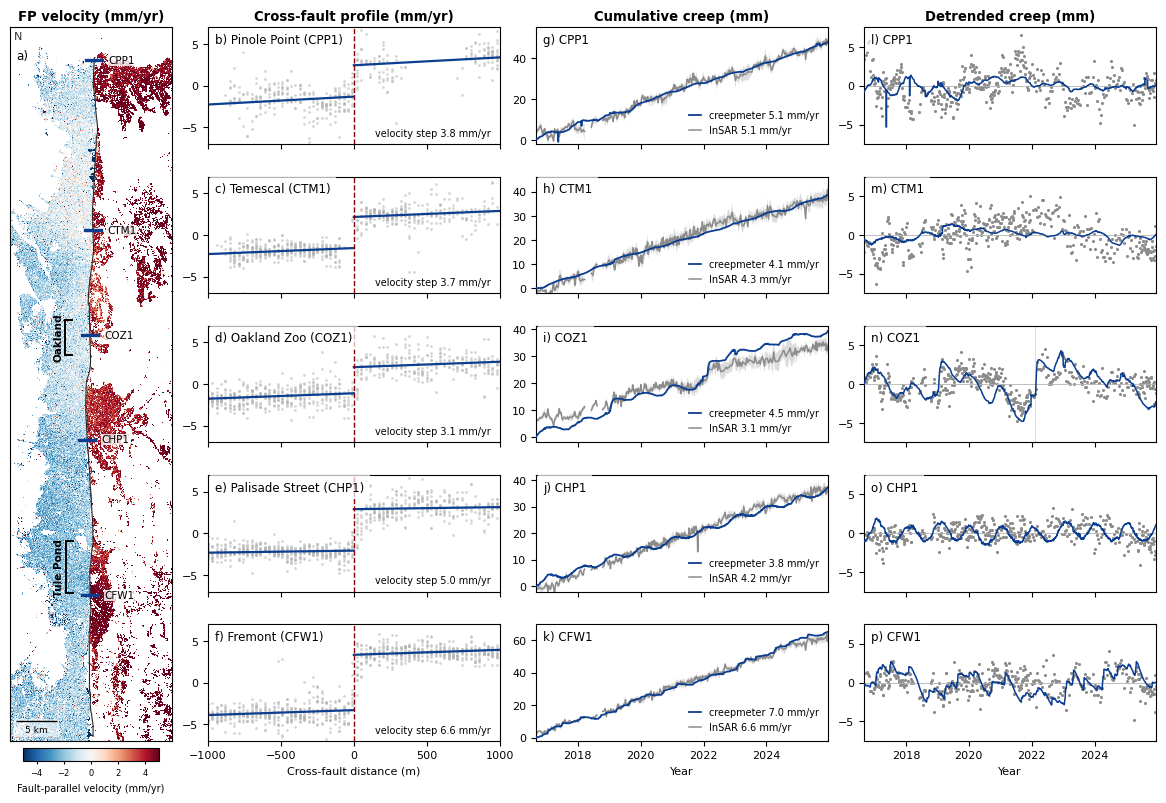

In [6]:
plt.rcParams.update({"font.size": 8})
cm_blue, insar_grey = "#0b3d91", "0.55"
fp_clim, prof_ylim = 5.0, 7.0

with h5py.File(map_file, "r") as h:
    fp_map = h["fp_velocity"][:].astype(float)
    attrs = {k: (v.decode() if isinstance(v, bytes) else str(v)) for k, v in h.attrs.items()}
fp_map[fp_map == 0] = np.nan
prof = pd.read_csv(common_paths["fault_profiles"])
utm = pyproj.Transformer.from_crs(4326, int(attrs["EPSG"]), always_xy=True)
fe, fn = utm.transform(prof["ft_lon"].values, prof["ft_lat"].values)
th = np.deg2rad(strike)
ae, an = np.sin(th), np.cos(th); pe, pn = -np.cos(th), np.sin(th)
u_tr = fe * ae + fn * an; v_tr = fe * pe + fn * pn
u_pin = float(u_tr[-1]); v0 = float(np.median(v_tr))


def to_uv(lon, lat):
    e, n = utm.transform(np.asarray(lon, float), np.asarray(lat, float))
    return ((e * pe + n * pn) - v0) / 1000.0, ((e * ae + n * an) - u_pin) / 1000.0


# the map on the rotated frame (v across, u along), nearest-neighbour lookup
u_south = (float(u_tr[0]) - u_pin) / 1000.0
ug = np.arange(-3.5, u_south + 0.6, 0.09); vg = np.arange(-map_half_km, map_half_km + 0.09, 0.09)
V, U = np.meshgrid(vg, ug)
E = (V * 1000.0 + v0) * pe + (U * 1000.0 + u_pin) * ae
N = (V * 1000.0 + v0) * pn + (U * 1000.0 + u_pin) * an
x0, dx = float(attrs["X_FIRST"]), float(attrs["X_STEP"]); y0, dy = float(attrs["Y_FIRST"]), float(attrs["Y_STEP"])
ci = np.round((E - x0) / dx).astype(int); ri = np.round((N - y0) / dy).astype(int)
ok = (ci >= 0) & (ci < fp_map.shape[1]) & (ri >= 0) & (ri < fp_map.shape[0])
ob_z = np.full(U.shape, np.nan); ob_z[ok] = fp_map[ri[ok], ci[ok]]
ob_ext = [float(vg[0]), float(vg[-1]), float(ug[-1]), float(ug[0])]
# display reference: the CTM1-COZ1 fault-straddling patch, so the fault sits at zero
u_cm = {code: to_uv(lo, la)[1] for code, la, lo, name in creepmeters}
lo_u, hi_u = sorted([u_cm["CTM1"], u_cm["COZ1"]])
ref_mean = np.nanmean(ob_z[np.ix_((ug >= lo_u) & (ug <= hi_u), np.abs(vg) <= ref_patch_km)])

# section brackets: the MEASURED extents from notebook 04 (section_lengths.csv):
# Tule Pond = the length of fault hosting the events, Oakland = its 75% band
sl = pd.read_csv(lengths_file).set_index("name")
seg_ext = {"Tule Pond": (sl.loc["tulepond_creep_length", "lat_lo"], sl.loc["tulepond_creep_length", "lat_hi"]),
           "Oakland": (sl.loc["oakland_band75", "lat_lo"], sl.loc["oakland_band75", "lat_hi"])}
print("section brackets (lat):", {k: (round(v[0], 4), round(v[1], 4)) for k, v in seg_ext.items()})
events_coz = pd.read_csv(events_file).query("segment == 'COZ1'") if os.path.exists(events_file) else pd.DataFrame()

fig = plt.figure(figsize=(12.0, 8.2))
gs = fig.add_gridspec(5, 4, width_ratios=[0.72, 1.30, 1.30, 1.30], hspace=0.28, wspace=0.14,
                      left=0.04, right=0.995, top=0.94, bottom=0.07)
axm = fig.add_subplot(gs[:, 0])
im = axm.imshow(np.ma.masked_invalid(ob_z - ref_mean), cmap="RdBu_r", vmin=-fp_clim, vmax=fp_clim,
                extent=ob_ext, interpolation="none", aspect="auto", origin="upper")
tv, tu = to_uv(prof["ft_lon"].values, prof["ft_lat"].values)
axm.plot(tv, tu, "-", color="0.15", lw=0.8, zorder=4)
for code, la, lo, name in creepmeters:
    cv, cu = to_uv(lo, la)
    axm.plot([cv - 1.0, cv + 1.0], [cu, cu], "-", color=cm_blue, lw=2.4, zorder=5)
    axm.text(cv + 1.8, cu, code, fontsize=7.5, va="center", ha="left", zorder=6,
             bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.5))
for name, (la_lo, la_hi) in seg_ext.items():
    uu = []
    for la in (la_lo, la_hi):
        j = int(np.argmin(np.abs(prof["ft_lat"].values - la)))
        uu.append(to_uv(prof["ft_lon"].values[j], prof["ft_lat"].values[j]))
    bx = max(min(u[0] for u in uu) - 3.0, ob_ext[0] + 1.4)
    axm.plot([bx, bx], [uu[0][1], uu[1][1]], "-", color="k", lw=1.4, zorder=6)
    for _v, _u in uu:
        axm.plot([bx, bx + 0.8], [_u, _u], "-", color="k", lw=1.4, zorder=6)
    axm.text(bx - 0.9, 0.5 * (uu[0][1] + uu[1][1]), name, fontsize=7.5, fontweight="bold", va="center", ha="center", rotation=90)
axm.set_xlim(ob_ext[0], ob_ext[1]); axm.set_ylim(ob_ext[2], ob_ext[3]); axm.set_xticks([]); axm.set_yticks([])
sbar = AnchoredSizeBar(axm.transData, 5, "5 km", loc="lower left", frameon=True, pad=0.3, borderpad=0.4, sep=3,
                       size_vertical=0, fontproperties=FontProperties(size=6.5))
sbar.patch.set(facecolor="white", alpha=0.6, edgecolor="none"); axm.add_artist(sbar)
axm.text(0.05, 0.995, "N", transform=axm.transAxes, fontsize=8, va="top", ha="center", color="0.2")
axm.text(0.04, 0.97, "a)", transform=axm.transAxes, va="top", fontsize=8.5,
         bbox=dict(facecolor="white", edgecolor="none", alpha=0.7))
cb = fig.colorbar(im, cax=axm.inset_axes([0.08, -0.028, 0.84, 0.018]), orientation="horizontal")
cb.set_label("Fault-parallel velocity (mm/yr)", fontsize=7); cb.ax.tick_params(labelsize=6, length=2)

letters = ("bcdef", "ghijk", "lmnop")
first = {}
for i, (code, la, lo, name) in enumerate(creepmeters):
    r = df.loc[code]
    ct, ccum = cm_data[code]
    # col 2: cross-fault velocity profile with the step
    ax2 = fig.add_subplot(gs[i, 1])
    s = xf[(xf["code"] == code) & (xf["dist_m"].abs() <= max_dist_m)]
    d = s["dist_m"].values.astype(float); v = s["fp_vel"].values.astype(float); v = v - v.mean()
    ax2.scatter(d, v, s=4, color="0.7", alpha=0.55, lw=0)
    G = np.column_stack([np.ones_like(d), d, (d > 0).astype(float)])
    a_, b_, step_mm = np.linalg.lstsq(G, v, rcond=None)[0]
    xw, xe = np.array([-max_dist_m, 0.0]), np.array([0.0, max_dist_m])
    ax2.plot(xw, a_ + b_ * xw, color=cm_blue, lw=1.6); ax2.plot(xe, a_ + b_ * xe + step_mm, color=cm_blue, lw=1.6)
    ax2.annotate(f"velocity step {step_mm:.1f} mm/yr", xy=(0.97, 0.05), xycoords="axes fraction", ha="right", va="bottom",
                 fontsize=7, bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=0.5))
    ax2.axvline(0, color="darkred", lw=1.0, ls="--")
    ax2.set_xlim(-max_dist_m, max_dist_m); ax2.set_ylim(-prof_ylim, prof_ylim); ax2.set_xticks([-1000, -500, 0, 500, 1000])
    ax2.text(0.025, 0.95, f"{letters[0][i]}) {name} ({code})", transform=ax2.transAxes, va="top", fontsize=8.5,
             bbox=dict(facecolor="white", edgecolor="none", alpha=0.7))
    # col 3: cumulative creep
    ax3 = fig.add_subplot(gs[i, 2])
    ax3.plot(ct, ccum, color=cm_blue, lw=1.3, zorder=3, label=f"creepmeter {r.cm_rate:.1f} mm/yr")
    t, mean, std, _n = stack_insar(fp_ts, la)
    mok = np.isfinite(mean)
    cm_at_t = np.interp(t[mok], ct, ccum)
    mean_disp = mean + float(np.mean(cm_at_t - mean[mok]))     # display alignment only; the rate is untouched
    ax3.fill_between(t, mean_disp - std, mean_disp + std, color=insar_grey, alpha=0.30, lw=0)
    ax3.plot(t, mean_disp, color=insar_grey, lw=1.1, zorder=2, label=f"InSAR {r.cr_rate:.1f} mm/yr")
    ax3.set_xlim(t0, t1); ax3.set_ylim(bottom=-2); ax3.set_xticks([2018, 2020, 2022, 2024])
    ax3.legend(fontsize=7, loc="lower right", frameon=False, handlelength=1.3)
    ax3.text(0.025, 0.95, f"{letters[1][i]}) {code}", transform=ax3.transAxes, va="top", fontsize=8.5,
             bbox=dict(facecolor="white", edgecolor="none", alpha=0.7))
    # col 4: detrended
    ax4 = fig.add_subplot(gs[i, 3])
    if code == "COZ1" and len(events_coz):
        for _, ev in events_coz.iterrows():
            ax4.axvspan(ev["onset_lo"], ev["onset_hi"], color="#F5B400", alpha=0.45, lw=0, zorder=0)
    ax4.plot(ct, utils.detrend(ct, ccum), color=cm_blue, lw=1.1, zorder=3)
    ax4.scatter(t, utils.detrend(t, mean), s=5, color=insar_grey, lw=0, zorder=2)
    ax4.axhline(0, color="0.7", lw=0.6)
    ax4.set_xlim(t0, t1); ax4.set_xticks([2018, 2020, 2022, 2024]); ax4.set_ylim(-fp_clim * 1.5, fp_clim * 1.5)
    ax4.text(0.025, 0.95, f"{letters[2][i]}) {code}", transform=ax4.transAxes, va="top", fontsize=8.5,
             bbox=dict(facecolor="white", edgecolor="none", alpha=0.7))
    for ax in (ax2, ax3, ax4):
        if i < len(creepmeters) - 1:
            ax.tick_params(labelbottom=False)
    if i == len(creepmeters) - 1:
        ax2.set_xlabel("Cross-fault distance (m)"); ax3.set_xlabel("Year"); ax4.set_xlabel("Year")
    if i == 0:
        first = {"prof": ax2, "cum": ax3, "det": ax4}
fig.canvas.draw()
for ax, txt in [(axm, "FP velocity (mm/yr)"), (first["prof"], "Cross-fault profile (mm/yr)"),
                (first["cum"], "Cumulative creep (mm)"), (first["det"], "Detrended creep (mm)")]:
    p = ax.get_position()
    fig.text(0.5 * (p.x0 + p.x1), 0.945, txt, ha="center", va="bottom", fontsize=9.5, fontweight="bold")
fig_val = os.path.join(fig_dir, f"figS_validation_cohmap{coh_velocity:g}_{params}_profile{max_dist_m:.0f}m_stack{stack_max}x{stack_km * 1000:.0f}m.png")
fig.savefig(fig_val, dpi=200, bbox_inches="tight"); fig.savefig(fig_val.replace(".png", ".pdf"), bbox_inches="tight")
print("Saved figure to:", fig_val)
plt.show()

## The aperture ladder, from the frozen sweep

Every cross-fault bin that was scored, re-scored here on one FIXED stack
(4 rows within 0.4 km of each creepmeter, no widening) so the bins are
comparable: the five-station rate RMS (long-term agreement), the fraction of
the trace with data (completeness), and at COZ1 the detrended correlation
(event shape) and the fraction of the creepmeter's two event steps
recovered (event amplitude). Bins reaching the trace agree worst on rate
(the phase-linking smoothing dilutes the step over ~55 to 65 m) but best on
event shape; the 30 to 150 m bin is the compromise carried forward.

In [7]:
def event_step(t, cum, s, e):
    """Slip across one event window against the local inter-event trend
    (fit on the collars either side, never inside), mean residual after minus before."""
    pre = (t >= s - collar_yr) & (t < s); post = (t > e) & (t <= e + collar_yr)
    if pre.sum() < 5 or post.sum() < 5:
        return np.nan
    fit = np.isfinite(cum) & (pre | post)
    if fit.sum() < 12:
        return np.nan
    rres = cum - np.polyval(np.polyfit(t[fit], cum[fit], 1), t)
    return float(np.nanmean(rres[post]) - np.nanmean(rres[pre]))


def load_fp(cdir):
    fp = pd.read_csv(os.path.join(cdir, "fp_ts.csv"), index_col=0)
    fp.columns = fp.columns.astype(float); fp.index = fp.index.astype(float)
    return fp


coz1_lat = [la for c, la, lo, n in creepmeters if c == "COZ1"][0]
ladder_rows = []
for setname, bins in (("fixed", fixed_width), ("growing", [b for b in growing if b not in fixed_width]),
                      ("original", original), ("inner", [b for b in inner_edge if b not in fixed_width + growing + original])):
    for inner, outer in bins:
        tag = f"ap{inner}-{outer}m_coh{ladder_coh:g}_mp{min_points}"
        cdir = os.path.join(common_paths["sweep_dir"], tag)
        if not os.path.isdir(cdir):
            print(f"  missing, skipped: {tag}")
            continue
        fp = load_fp(cdir)
        # rate RMS over the stations where the fixed stack can be formed
        d_cross = []
        for code, la, lo, name in creepmeters:
            st = stack_insar(fp, la, half_km=ladder_stack_km, n_stack=ladder_n_stack, exact=True)
            if st is None:
                continue
            t, mean, _, _ = st; ok = np.isfinite(mean)
            ct, ccum = cm_data[code]
            d_cross.append(np.polyfit(t[ok], mean[ok], 1)[0] - np.polyfit(ct, ccum, 1)[0])
        # COZ1: detrended correlation and step fraction
        st = stack_insar(fp, coz1_lat, half_km=ladder_stack_km, n_stack=ladder_n_stack, exact=True)
        det_r = frac = resid_sd = np.nan
        if st is not None:
            t, mean, _, _ = st; ok = np.isfinite(mean); ti, ins = t[ok], mean[ok]
            ct, ccum = cm_data["COZ1"]; cmi = np.interp(ti, ct, ccum)
            di, dc = utils.detrend(ti, ins), utils.detrend(ti, cmi); gd = np.isfinite(di) & np.isfinite(dc)
            det_r = float(np.corrcoef(di[gd], dc[gd])[0, 1])
            si = np.array([event_step(ti, ins, a, b) for a, b in coz1_events]); sc = np.array([event_step(ti, cmi, a, b) for a, b in coz1_events])
            g = np.isfinite(si) & np.isfinite(sc) & (sc > 0)
            frac = float(np.sum(si[g]) / np.sum(sc[g])) if g.any() else np.nan
            A = np.c_[np.ones(ok.sum()), ti - ti.mean(), np.sin(2 * np.pi * ti), np.cos(2 * np.pi * ti)]
            resid_sd = float(np.std(ins - A @ np.linalg.lstsq(A, ins, rcond=None)[0]))
        ladder_rows.append(dict(set=setname, tag=tag, inner=inner, outer=outer, centre=(inner + outer) / 2, width=outer - inner,
                                n_stations=len(d_cross), valid=100.0 * fp.shape[0] / len(prof),
                                rate_rms=float(np.sqrt(np.mean(np.square(d_cross)))) if d_cross else np.nan,
                                coz1_det_r=det_r, coz1_step_frac=frac, coz1_resid_sd_mm=resid_sd))
ladder = pd.DataFrame(ladder_rows)
ladder.to_csv(os.path.join(out_dir, "sweep_ladder_scores.csv"), index=False)
print(ladder.drop(columns=["tag"]).round(3).to_string(index=False))
sel = ladder[(ladder.inner == selected[0]) & (ladder.outer == selected[1])].iloc[0]
print("")
print(f"selected bin {selected[0]}-{selected[1]} m at coherence {ladder_coh}: rate RMS {sel.rate_rms:.2f} mm/yr on {sel.n_stations} stations, "
      f"{sel.valid:.0f}% of the trace, COZ1 det r {sel.coz1_det_r:.2f}, step recovered {100 * sel.coz1_step_frac:.0f}%")

# the chosen bin at the three coherence thresholds (the sweep's own summary table):
# the threshold is second order for the rate and the paper runs at 0.7 for coverage
sw = pd.read_csv(os.path.join(common_paths["sweep_dir"], "sweep_summary_mp5.csv"))
sw = sw[sw.tag.str.startswith(f"ap{selected[0]}-{selected[1]}m")].sort_values("coh")
coh_rows = []
for _, r_ in sw.iterrows():
    fpc = load_fp(os.path.join(common_paths["sweep_dir"], r_.tag))
    coh_rows.append(dict(coh=r_.coh, rate_rms=r_.rate_rms, rate_bias=r_.rate_bias, n_crossings=fpc.shape[0]))
coh_tab = pd.DataFrame(coh_rows)
print(coh_tab.round(3).to_string(index=False))

     set  inner  outer  centre  width  n_stations  valid  rate_rms  coz1_det_r  coz1_step_frac  coz1_resid_sd_mm
   fixed      0    100    50.0    100           4 54.614     1.113       0.602           0.376             1.500
   fixed     50    150   100.0    100           5 59.039     0.626       0.512           0.393             1.696
   fixed    100    200   150.0    100           4 61.820     0.736       0.476           0.600             1.784
   fixed    150    250   200.0    100           4 58.534     0.673       0.477           0.599             1.974
   fixed    200    300   250.0    100           4 57.269     0.822       0.345           0.766             2.252
   fixed    300    400   350.0    100           4 54.235     0.857       0.196           0.223             2.344
   fixed    400    500   450.0    100           4 53.982     1.049       0.308           0.538             2.632
 growing    100    300   200.0    200           4 69.659     0.764       0.418           0.622  

Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/figS_binning_ladder_coh0.9_mp5_stack4x0.4km.png


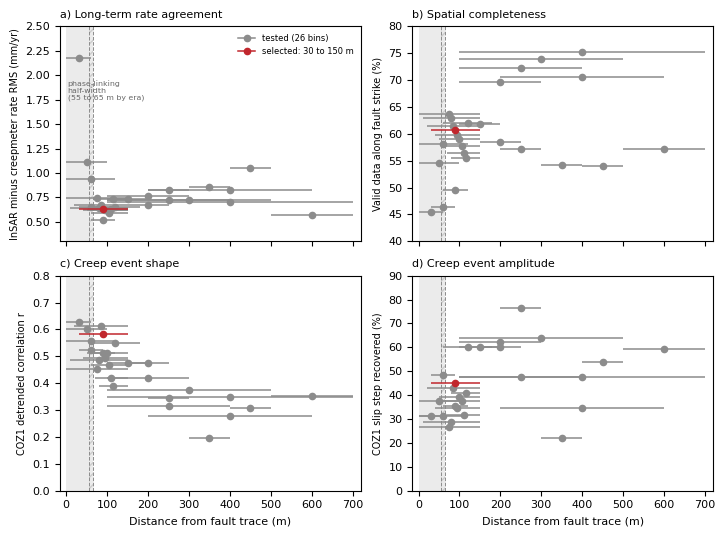

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharex=True)
axes = axes.ravel()
ordered = ladder.assign(_z=[(r.inner, r.outer) == selected for r in ladder.itertuples()]).sort_values("_z")


def draw(ax, col, scale=1.0):
    for _, r in ordered.iterrows():
        if not np.isfinite(r[col]):
            continue
        y = scale * r[col]; sel_ = (r.inner, r.outer) == selected
        c, z = ("#C1272D", 6) if sel_ else ("0.55", 2)
        ax.plot([r.inner, r.outer], [y, y], "-", color=c, lw=1.1, zorder=z, solid_capstyle="butt")
        ax.plot(r.centre, y, "o", ms=4.5, color=c, zorder=z + 1)


for ax in axes:
    ax.axvspan(0, kernel_m[0], facecolor="0.92", zorder=0)
    ax.axvspan(*kernel_m, facecolor="0.92", zorder=0, hatch="///", edgecolor="0.80", lw=0)
    for k in kernel_m:
        ax.axvline(k, color="0.55", lw=0.7, ls="--", zorder=1)
    ax.set_xlim(-15, 720)
axes[0].text(3, 1.95, "phase-linking\nhalf-width\n(55 to 65 m by era)", fontsize=5.6, color="0.40", va="top")
for ax, col, ylab, ylim, title, scale in ((axes[0], "rate_rms", "InSAR minus creepmeter rate RMS (mm/yr)", (0.3, 2.5), "a) Long-term rate agreement", 1),
                                          (axes[1], "valid", "Valid data along fault strike (%)", (40, 80), "b) Spatial completeness", 1),
                                          (axes[2], "coz1_det_r", "COZ1 detrended correlation r", (0, 0.8), "c) Creep event shape", 1),
                                          (axes[3], "coz1_step_frac", "COZ1 slip step recovered (%)", (0, 90), "d) Creep event amplitude", 100)):
    draw(ax, col, scale); ax.set_ylabel(ylab, fontsize=7); ax.set_ylim(*ylim); ax.set_title(title, loc="left", fontsize=8)
for ax in axes[2:]:
    ax.set_xlabel("Distance from fault trace (m)")
axes[0].legend(handles=[Line2D([], [], color="0.55", lw=1.1, marker="o", ms=4.5, label=f"tested ({len(ladder)} bins)"),
                        Line2D([], [], color="#C1272D", lw=1.1, marker="o", ms=4.5, label=f"selected: {selected[0]} to {selected[1]} m")],
               frameon=False, fontsize=6, loc="upper right")
fig.tight_layout()
fig_lad = os.path.join(fig_dir, f"figS_binning_ladder_coh{ladder_coh:g}_mp{min_points}_stack{ladder_n_stack}x{ladder_stack_km}km.png")
fig.savefig(fig_lad, dpi=300); fig.savefig(fig_lad.replace(".png", ".pdf"))
print("Saved figure to:", fig_lad)
plt.show()

## REGISTER

In [9]:
L += ["", f"APERTURE LADDER (frozen sweep at coherence {ladder_coh}, fixed 4-row stack within 0.4 km)",
      ladder.drop(columns=["tag"]).round(3).to_string(index=False), "",
      f"chosen bin {selected[0]}-{selected[1]} m by coherence threshold:", coh_tab.round(3).to_string(index=False)]
sidecar = REG.sidecar("05_validation", L)
for c, r in df.iterrows():
    for key, lab in (("cm", "creepmeter"), ("cr", "crossing"), ("st", "step")):
        REG.register(f"05_{c}_{lab}_rate_mm_yr", r[f"{key}_rate"], "mm/yr", 2, where="M4, Fig S validation", cell="bootstrap", sidecar=sidecar)
        REG.register(f"05_{c}_{lab}_ci_lo", r[f"{key}_lo"], "mm/yr", 2, where="M4", cell="bootstrap", sidecar=sidecar)
        REG.register(f"05_{c}_{lab}_ci_hi", r[f"{key}_hi"], "mm/yr", 2, where="M4", cell="bootstrap", sidecar=sidecar)
    REG.register(f"05_{c}_det_r", r.det_r, "1", 2, where="M4", cell="bootstrap", sidecar=sidecar)
    REG.register(f"05_{c}_det_rmse_mm", r.det_rmse, "mm", 2, where="M4", cell="bootstrap", sidecar=sidecar)
REG.register("05_rate_rms_mm_yr", agr["cross"]["rms"], "mm/yr", 2, where="P2, M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_bias_mm_yr", agr["cross"]["bias"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_maxabs_mm_yr", agr["cross"]["maxabs"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_rate_rms_excl_coz1_mm_yr", agr["cross_excl_coz1"]["rms"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_step_rms_mm_yr", agr["step"]["rms"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_step_bias_mm_yr", agr["step"]["bias"], "mm/yr", 2, where="M4", cell="agreement", sidecar=sidecar)
REG.register("05_noise_floor_det_rmse_mm", floor_rmse, "mm", 2, where="P2, M4", cell="noise-floor", sidecar=sidecar)
REG.register("05_det_rmse_min_mm", df.det_rmse.min(), "mm", 2, where="M4", cell="noise-floor", sidecar=sidecar)
REG.register("05_det_rmse_max_mm", df.det_rmse.max(), "mm", 2, where="M4", cell="noise-floor", sidecar=sidecar)
REG.register("05_noise_floor_steady_std_mm", floor_run10, "mm", 2, where="M4 (alternative definition)", cell="noise-floor", sidecar=sidecar)
for _, r_ in coh_tab.iterrows():
    REG.register(f"05_coh{r_.coh:g}_rate_rms_mm_yr", r_.rate_rms, "mm/yr", 2, where="M3", cell="ladder", sidecar=sidecar)
    REG.register(f"05_coh{r_.coh:g}_n_crossings", int(r_.n_crossings), "count", 0, where="M3", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_n_bins", len(ladder), "count", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_rate_rms", sel.rate_rms, "mm/yr", 2, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_valid_pct", sel.valid, "pct", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_coz1_det_r", sel.coz1_det_r, "1", 2, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.register("05_ladder_selected_coz1_step_pct", 100 * sel.coz1_step_frac, "pct", 0, where="M3, Fig S ladder", cell="ladder", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/05_validation/05_validation_stats.txt
  registered 05_CPP1_creepmeter_rate_mm_yr = 5.05 mm/yr  -> M4, Fig S validation
  registered 05_CPP1_creepmeter_ci_lo = 4.95 mm/yr  -> M4
  registered 05_CPP1_creepmeter_ci_hi = 5.15 mm/yr  -> M4
  registered 05_CPP1_crossing_rate_mm_yr = 5.11 mm/yr  -> M4, Fig S validation
  registered 05_CPP1_crossing_ci_lo = 4.82 mm/yr  -> M4
  registered 05_CPP1_crossing_ci_hi = 5.39 mm/yr  -> M4
  registered 05_CPP1_step_rate_mm_yr = 3.77 mm/yr  -> M4, Fig S validation
  registered 05_CPP1_step_ci_lo = 2.56 mm/yr  -> M4
  registered 05_CPP1_step_ci_hi = 4.88 mm/yr  -> M4
  registered 05_CPP1_det_r = 0.26 1  -> M4
  registered 05_CPP1_det_rmse_mm = 1.86 mm  -> M4
  registered 05_CTM1_creepmeter_rate_mm_yr = 4.11 mm/yr  -> M4, Fig S validation


  registered 05_CTM1_creepmeter_ci_lo = 4.01 mm/yr  -> M4
  registered 05_CTM1_creepmeter_ci_hi = 4.22 mm/yr  -> M4
  registered 05_CTM1_crossing_rate_mm_yr = 4.30 mm/yr  -> M4, Fig S validation
  registered 05_CTM1_crossing_ci_lo = 4.03 mm/yr  -> M4
  registered 05_CTM1_crossing_ci_hi = 4.59 mm/yr  -> M4
  registered 05_CTM1_step_rate_mm_yr = 3.73 mm/yr  -> M4, Fig S validation
  registered 05_CTM1_step_ci_lo = 3.20 mm/yr  -> M4
  registered 05_CTM1_step_ci_hi = 4.23 mm/yr  -> M4
  registered 05_CTM1_det_r = 0.40 1  -> M4
  registered 05_CTM1_det_rmse_mm = 1.82 mm  -> M4
  registered 05_COZ1_creepmeter_rate_mm_yr = 4.48 mm/yr  -> M4, Fig S validation
  registered 05_COZ1_creepmeter_ci_lo = 4.14 mm/yr  -> M4
  registered 05_COZ1_creepmeter_ci_hi = 4.80 mm/yr  -> M4
  registered 05_COZ1_crossing_rate_mm_yr = 3.15 mm/yr  -> M4, Fig S validation
  registered 05_COZ1_crossing_ci_lo = 2.89 mm/yr  -> M4
  registered 05_COZ1_crossing_ci_hi = 3.38 mm/yr  -> M4


  registered 05_COZ1_step_rate_mm_yr = 3.14 mm/yr  -> M4, Fig S validation
  registered 05_COZ1_step_ci_lo = 2.62 mm/yr  -> M4
  registered 05_COZ1_step_ci_hi = 3.67 mm/yr  -> M4
  registered 05_COZ1_det_r = 0.58 1  -> M4
  registered 05_COZ1_det_rmse_mm = 1.68 mm  -> M4
  registered 05_CHP1_creepmeter_rate_mm_yr = 3.79 mm/yr  -> M4, Fig S validation
  registered 05_CHP1_creepmeter_ci_lo = 3.73 mm/yr  -> M4
  registered 05_CHP1_creepmeter_ci_hi = 3.84 mm/yr  -> M4
  registered 05_CHP1_crossing_rate_mm_yr = 4.24 mm/yr  -> M4, Fig S validation
  registered 05_CHP1_crossing_ci_lo = 4.14 mm/yr  -> M4
  registered 05_CHP1_crossing_ci_hi = 4.34 mm/yr  -> M4
  registered 05_CHP1_step_rate_mm_yr = 4.98 mm/yr  -> M4, Fig S validation
  registered 05_CHP1_step_ci_lo = 4.32 mm/yr  -> M4


  registered 05_CHP1_step_ci_hi = 5.62 mm/yr  -> M4
  registered 05_CHP1_det_r = -0.18 1  -> M4
  registered 05_CHP1_det_rmse_mm = 1.58 mm  -> M4
  registered 05_CFW1_creepmeter_rate_mm_yr = 6.99 mm/yr  -> M4, Fig S validation
  registered 05_CFW1_creepmeter_ci_lo = 6.76 mm/yr  -> M4
  registered 05_CFW1_creepmeter_ci_hi = 7.23 mm/yr  -> M4
  registered 05_CFW1_crossing_rate_mm_yr = 6.59 mm/yr  -> M4, Fig S validation
  registered 05_CFW1_crossing_ci_lo = 6.46 mm/yr  -> M4
  registered 05_CFW1_crossing_ci_hi = 6.70 mm/yr  -> M4
  registered 05_CFW1_step_rate_mm_yr = 6.64 mm/yr  -> M4, Fig S validation
  registered 05_CFW1_step_ci_lo = 6.18 mm/yr  -> M4
  registered 05_CFW1_step_ci_hi = 7.09 mm/yr  -> M4
  registered 05_CFW1_det_r = 0.35 1  -> M4
  registered 05_CFW1_det_rmse_mm = 1.47 mm  -> M4
  registered 05_rate_rms_mm_yr = 0.66 mm/yr  -> P2, M4
  registered 05_rate_bias_mm_yr = -0.21 mm/yr  -> M4
  registered 05_rate_maxabs_mm_yr = 1.33 mm/yr  -> M4
  registered 05_rate_rms_excl_co

  registered 05_det_rmse_min_mm = 1.47 mm  -> M4
  registered 05_det_rmse_max_mm = 1.86 mm  -> M4
  registered 05_noise_floor_steady_std_mm = 1.91 mm  -> M4 (alternative definition)
  registered 05_coh0.7_rate_rms_mm_yr = 0.72 mm/yr  -> M3
  registered 05_coh0.7_n_crossings = 609 count  -> M3
  registered 05_coh0.8_rate_rms_mm_yr = 0.69 mm/yr  -> M3
  registered 05_coh0.8_n_crossings = 565 count  -> M3
  registered 05_coh0.9_rate_rms_mm_yr = 0.63 mm/yr  -> M3
  registered 05_coh0.9_n_crossings = 480 count  -> M3
  registered 05_ladder_n_bins = 26 count  -> M3, Fig S ladder
  registered 05_ladder_selected_rate_rms = 0.63 mm/yr  -> M3, Fig S ladder
  registered 05_ladder_selected_valid_pct = 61 pct  -> M3, Fig S ladder
  registered 05_ladder_selected_coz1_det_r = 0.58 1  -> M3, Fig S ladder
  registered 05_ladder_selected_coz1_step_pct = 45 pct  -> M3, Fig S ladder


Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'